In [20]:
import pandas as pd
import numpy as np

df = pd.read_csv("./datasets/OnlineRetail.csv", encoding='latin1')
df = df.dropna()
df = df[(df['UnitPrice'] > 0) & (df['Quantity'] > 0)]
df = df[["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "CustomerID"]]

df['Amount'] = df['UnitPrice'] * df['Quantity']

df = df.groupby("CustomerID").agg({
    'InvoiceNo' : 'nunique',
    'StockCode' : 'nunique',
    'Quantity' : 'sum',
    'Amount' : 'sum'
}).reset_index()

df.columns = ['CustomerID', 'InvoiceCount', 'StockCount', 'TotalQ', 'TotalA']
df['Category'] = pd.qcut(df['TotalA'].rank(method = 'first'), q = 3, labels = ["Low", "Medium", "high"])
df


,CustomerID,InvoiceCount,StockCount,TotalQ,TotalA,Category
0,12346.0,1,1,74215,77183.60,high
1,12347.0,7,103,2458,4310.00,high
2,12348.0,4,22,2341,1797.24,high
3,12349.0,1,73,631,1757.55,high
4,12350.0,1,17,197,334.40,Low
...,...,...,...,...,...,...
4333,18280.0,1,10,45,180.60,Low
4334,18281.0,1,7,54,80.82,Low
4335,18282.0,2,12,103,178.05,Low
4336,18283.0,16,263,1397,2094.88,high


In [21]:
X = df[["InvoiceCount", "StockCount", "TotalQ", "TotalA"]]
Y = df["Category"]

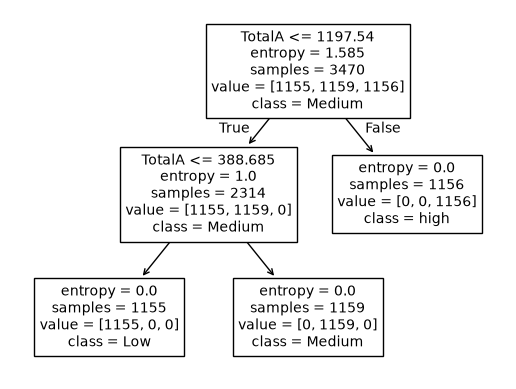

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

xtr, xte, ytr, yte = train_test_split(X, Y, test_size = 0.2)

dte = DecisionTreeClassifier(criterion='entropy', max_depth=4)
dte.fit(xtr, ytr)
labels = dte.predict(xte)

plot_tree(dte, feature_names=["InvoiceCount", "StockCount", "TotalQ", "TotalA"], class_names=dte.classes_)
plt.show()


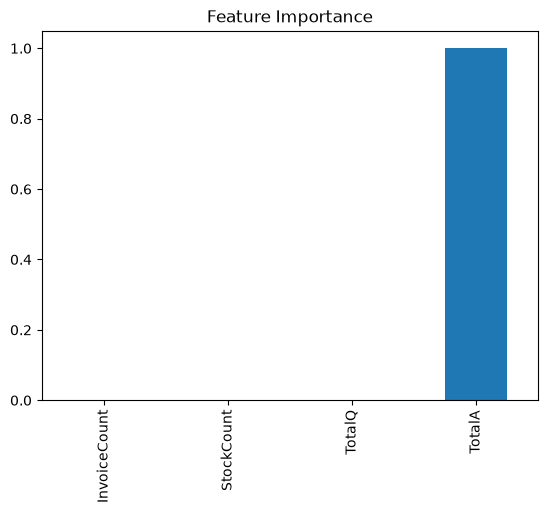

In [27]:
importance = pd.Series(dte.feature_importances_, index = X.columns)
importance.plot(kind='bar', title='Feature Importance')
plt.show()